# Analytical sequence-space perturbation

Notebook 1 used numerical differentiation to calculate size, history, and risk effects. We now differentiate the household equations analytically, following the paper's section 4.5, which makes it practical to calculate many more history effects.

This notebook has three main parts. First, we check the analytical derivatives against numerical differentiation and compare their computation times. Second, we combine them with the GE one-shot principle to obtain the full second-order solution over the paper's history window. Finally, we calculate the third-order terms needed for fifth-order-accurate covariances, including the effects of risk on shock transmission, and use them to calculate the variance and first autocovariance of output.

Since we're manually implementing most of the sequence-space calculations in this notebook, some parts of it are fairly dense. For routines that automate what we do here, see notebook 3.

## 0. Setup

We use the same household calibration as notebooks 0 and 1, with steady-state quarterly GDP normalized to one. As in the paper, we retain responses for $T=300$ quarters and history lags of less than $L=100$ quarters relative to the most recent shock.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
from smooth_sim.model import paper_household
from sequence_space.paths import first_order, second_order, third_order
from sequence_space.jacobian import income_jacobian_analytical
from sequence_space.risk_terms import stationary_response
from analytical_simple.backward import Backward as SimpleBackward
from analytical_simple.forward import Forward as SimpleForward
from analytical_fast.backward import Backward
from analytical_fast.forward import Forward

plt.rcParams["figure.figsize"] = (7, 3.5)
T, L, rho_B = 300, 100, 0.95
hh, ss = paper_household()

## 1. Analytical and numerical derivatives

We begin in partial equilibrium with a one-time aggregate income shock, holding the interest rate and transfers fixed. Let $A(\nu)$ be the resulting asset path for a shock of size $\nu$. We compare its first three derivatives using the numerical stencils from notebook 1 and two implementations of analytical differentiation.

The routines `first_order`, `second_order`, and `third_order` in `sequence_space/paths.py` calculate household derivatives through the indicated order over the whole transition, for a given perturbation of the input paths. They use the one-period derivatives implemented in either `analytical_simple/` or `analytical_fast/`, working backward to obtain marginal-value and policy derivatives, then propagating distribution and asset derivatives forward.

The implementation in `analytical_simple/` prioritizes readability and closely follows the `backward.md` and `forward.md` notes. The implementation in `analytical_fast/` evaluates the same equations with a few changes for speed: it combines expectation products into one compiled loop with shared sparse indices, moves key derivative calculations into Numba-compiled routines, and reuses repeated squares and cubes.

First, we test analytical differentiation for accuracy, showing that it agrees closely with numerical differentiation, and that the two analytical implementations agree almost perfectly. For each derivative order, the table below reports the maximum absolute difference between the two methods over the response path, normalized by the maximum absolute value of the analytical response.

In [2]:
pe_inputs = np.zeros((T, 3))  # Household inputs: (r, Z, Tr)
pe_inputs[0, 1] = 1.          # unit shock to Z at date 0

# initialize objects that calculate analytical derivatives for one-period backward and forward steps
simple_backward, simple_forward = SimpleBackward(hh, ss), SimpleForward(hh, ss)
backward, forward = Backward(hh, ss), Forward(hh, ss)

def numerical_derivatives():
    def A(size):
        return hh.transition(ss, dZ=size*pe_inputs[:, 1])["A"]
    h1, h2, h3 = 1e-4, 2e-4, 1e-3
    A1 = (A(h1)-A(-h1))/(2*h1)
    A2 = (A(h2)-2*A(0.)+A(-h2))/h2**2
    A3 = (A(-3*h3)-8*A(-2*h3)+13*A(-h3)-13*A(h3)+8*A(2*h3)-A(3*h3))/(8*h3**3)
    return np.array([A1, A2, A3])

def analytical_derivatives(b, f):
    result = third_order(b, f, pe_inputs)
    return np.array([result["dA"], result["d2A"], result["d3A"]])

numerical = numerical_derivatives()
simple = analytical_derivatives(simple_backward, simple_forward)
fast = analytical_derivatives(backward, forward)
print("Order   Numerical vs analytical   Simple vs fast (relative max errors)")
for order in range(3):
    scale = np.max(abs(fast[order]))
    print(f"{order+1:3d}     {np.max(abs(numerical[order]-fast[order]))/scale:12.2e}"
          f"             {np.max(abs(simple[order]-fast[order]))/scale:12.2e}")
assert np.allclose(simple, fast, rtol=1e-10, atol=1e-10)

Order   Numerical vs analytical   Simple vs fast (relative max errors)
  1         1.54e-07                 2.03e-13
  2         3.59e-05                 1.52e-11
  3         2.83e-04                 1.59e-11


The numerical and analytical derivatives agree closely through third order, while the two analytical implementations agree with relative errors below $2\times10^{-11}$.

We next time another run of each method, which measures the cost of differentiation excluding one-time Numba compilation costs.

In [3]:
for name, calculation in [("Numerical", numerical_derivatives),
                          ("Analytical: simple", lambda: analytical_derivatives(simple_backward, simple_forward)),
                          ("Analytical: fast", lambda: analytical_derivatives(backward, forward))]:
    start = perf_counter()
    calculation()
    seconds = perf_counter()-start
    print(f"{name:22s} {seconds:.3f} s")

Numerical              14.980 s


Analytical: simple     0.374 s
Analytical: fast       0.143 s


In this run, the fast implementation of analytical differentiation is roughly two orders of magnitude faster than numerical differentiation. The gain will matter especially for history effects, where we will need to repeat these calculations many times. We use the fast implementation from now on.

## 2. Second-order general equilibrium

We now return to the IKC model from notebook 1. As before, a debt innovation finances a proportional tax cut, with its effect on debt decaying at $\rho_B=0.95$, and after-tax income adjusts so that household assets match government debt while the interest rate, government purchases, and lump-sum transfers remain fixed. With government spending fixed, output and consumption changes coincide, $\Delta Y_t=\Delta C_t$; we use output for the GE results.

We use analytical differentiation to obtain the single-shock size effects calculated numerically in notebook 1, then follow its PE treatment of anticipated risk and successive surprises. Here we also need to adjust income to clear the asset market. After comparing the size, history, and risk effects for two consecutive shocks, we extend the history calculation to shocks up to 99 quarters apart.

We first solve $JZ_1=B_1$ for $B_{1,t}=\rho_B^t$ to obtain the first-order income response. As in notebook 1, the first-order output response is $Y_{1,t}=Z_{1,t}+(1+r)B_{1,t-1}-B_{1,t}$, with $B_{1,-1}=0$.

In [4]:
# First-order GE income and output after one debt innovation.
J = income_jacobian_analytical(backward, forward, T)
u = np.zeros((T, 3))  # Household inputs (r, Z, Tr): only income responds.
debt = rho_B**np.arange(T)
u[:, 1] = np.linalg.solve(J, debt)
Y1 = u[:, 1]+(1+ss["r"])*np.concatenate(([0.], debt[:-1]))-debt

We next feed households the trial income path $Z_{ss}+\nu Z_1$, just as in notebook 1's second-order GE calculation. `second_order` returns the asset derivatives along this path and the derivatives of the distribution. We then use the one-shot principle (**Proposition 7**) to offset the second-order asset response with an income change. This gives the second-order size effects, stored as output derivatives in `Y_size`, because debt has no second-order response.

We save the household derivatives in `single2` to reuse when a second shock arrives. We follow the first shock for $T+L-1$ dates so that $T$ dates remain even if the next shock arrives $L-1$ quarters later, padding the income path with zeros beyond $T-1$.

In [5]:
# Household derivatives along the first-order income path, including its later effects.
single2 = second_order(backward, forward, np.concatenate((u, np.zeros((L-1, 3)))))
Y_size = np.linalg.solve(J, -single2["d2A"][:T])

### Anticipated risk

We now let households anticipate debt innovations with variance $\sigma^2$. As in notebook 1, we obtain the risky steady state by perturbing expectations of future marginal value. Here, however, government debt stays fixed when no innovations are realized, so income must adjust to offset the change in household asset demand.

We first need the marginal-value curvature $V_{a,00}$ associated with a debt innovation, including its second-order effect on equilibrium income. We already have this income response in `Y_size`, which we put into `u2` below, and `second_order(..., u, u2)` then differentiates the household response along $\nu u+\nu^2u_2/2$ to give us $V_{a,00}$.

With this curvature supplying the expectation shift, `stationary_response` analytically differentiates the perturbed-expectation steady state that we differentiated numerically in notebook 1. We use it to calculate how steady-state assets respond both to the expectation shift and to a permanent income change. Calling these derivatives $A_{\mathrm{risk}}$ and $A_Z$, respectively, the income adjustment that keeps assets unchanged is
$$Z_{\sigma\sigma}=-\frac{A_{\mathrm{risk}}}{A_Z}.$$
The same adjustment gives the output change. The plot below corresponds to paper **Figure B.5(a)** and expresses the output change as a percentage of steady-state GDP.

Risky steady-state income and output shift (GDP units): -0.003940


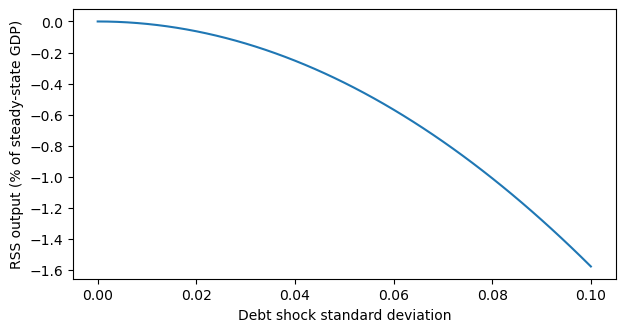

In [6]:
# Paper Figure B.5(a).
u2 = np.zeros_like(u)
u2[:, 1] = Y_size
equilibrium2 = second_order(backward, forward, u, u2)
Va00 = equilibrium2["d2Va0"]
income_ss = stationary_response(backward, forward, np.array([0., 1., 0.]), np.zeros(backward.shape))
direct_ss = stationary_response(backward, forward, np.zeros(3), Va00)
Y_risk = -direct_ss["dA"]/income_ss["dA"]
rss_du = np.array([0., Y_risk, 0.])
stationary = stationary_response(backward, forward, rss_du, Va00)
sigma = 0.05
print(f"Risky steady-state income and output shift (GDP units): {sigma**2*Y_risk/2:.6f}")
assert abs(stationary["dA"]) < 1e-7

sigmas = np.linspace(0., 0.10, 51)
plt.plot(sigmas, 50*sigmas**2*Y_risk)
plt.xlabel("Debt shock standard deviation"); plt.ylabel("RSS output (% of steady-state GDP)");

Anticipated risk lowers equilibrium output. Households want to save more, as in partial equilibrium, but fixed government debt prevents aggregate assets from rising, and in the background monetary policy (somewhat unrealistically for the steady state) fixes the real interest rate. Income falls until asset demand returns to its original level. At $\sigma=0.05$, the decline is about 0.004 of quarterly GDP, or 0.4% of GDP.

### History effects: successive surprises

Consider a debt shock $x$ at date $-l$, followed by an unanticipated shock $y$ at date 0, starting with consecutive shocks ($l=1$). As in notebook 1, we restart the household calculation when the second shock arrives, carrying forward the distribution left by the first. Here `initial_F` takes the first two derivatives of that distribution from `single2["dF"][l]` and `single2["d2F"][l]`. These describe the distribution entering date 0, after $l$ periods in which the second shock was not anticipated.

When the second shock arrives, we reset the clock to date 0. The earlier shock's remaining income response is then $Z_{1,t+l}$, while the new shock contributes $Z_{1,t}$. The helper `shifted(u, l, T)` drops the $l$ elapsed dates and pads the end with zeros to give $T$ dates after the second shock. Varying both shocks together therefore gives the input path `shifted(u, l, T)+u`.

We now apply the same polarization as in notebook 1, this time to household assets along this trial income path. Subtracting the two own-shock asset derivatives from the joint derivative and dividing by two gives $A_{xy}$. Debt is linear in the innovations, so it has no corresponding history effect. The one-shot principle gives the equilibrium income change needed to offset $A_{xy}$:
$$JZ_{xy}=-A_{xy}.$$
As in notebook 1, output and income have the same derivatives above first order, so $Y_{xy}=Z_{xy}$. This combines the history calculation from the second-order certainty correspondence (**Proposition 3**) with the GE solution.

For this history calculation, the first-order income paths are enough. Adding the second-order income response to either shock on its own would change the $x^2$ or $y^2$ terms, which cancel in the subtraction above and therefore do not affect the $xy$ interaction we are calculating.

In [7]:
def shifted(path, l, length):
    """Remaining response after the elapsed lag, padded to the requested horizon."""
    result = np.zeros((length,)+path.shape[1:])
    active = min(length, len(path)-l)
    result[:active] = path[l:l+active]
    return result

l = 1
inherited = (single2["dF"][l], single2["d2F"][l])
joint = second_order(backward, forward, shifted(u, l, T)+u, initial_F=inherited)
A_xx = single2["d2A"][l:l+T] # earlier shock, viewed from the second shock
A_yy = single2["d2A"][:T]    # current shock
A_xy = (joint["d2A"]-A_xx-A_yy)/2 # polarization along the trial income path
Y_xy = np.linalg.solve(J, -A_xy)

We now consider two consecutive unexpected debt shocks, $\epsilon_{-1}=\epsilon_0=0.10$, starting from the risky steady state with $\sigma=0.05$. As in notebook 1, we decompose the second-order response into the current size effect, previous size effect, history effect, and risk effect. The four curves sum to the second-order output correction relative to the deterministic steady state, with the first-order response omitted. This corresponds to paper **Figure B.6(a)**. Contributions are measured as percentages of steady-state GDP.

The current and previous size effects use `Y_size` starting at ages zero and one respectively, with the usual factor of $1/2$. The history effect is the additional response from their interaction. The dashed line is the risky-steady-state output shift, $\sigma^2Y_{\mathrm{risk}}/2$.

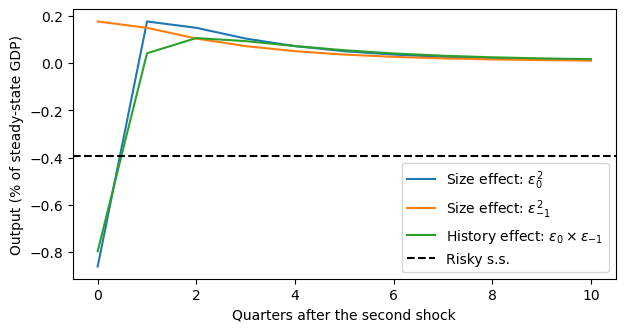

In [8]:
# Paper Figure B.6(a).
epsilon = 0.10
plt.plot(100*epsilon**2*Y_size[:11]/2, label=r"Size effect: $\epsilon_0^2$")
plt.plot(100*epsilon**2*Y_size[1:12]/2, label=r"Size effect: $\epsilon_{-1}^2$")
plt.plot(100*epsilon**2*Y_xy[:11], label=r"History effect: $\epsilon_0 \times \epsilon_{-1}$")
plt.axhline(100*sigma**2*Y_risk/2, color="k", linestyle="--", label="Risky s.s.")
plt.xlabel("Quarters after the second shock"); plt.ylabel("Output (% of steady-state GDP)")
plt.legend();

The size and history effects have the same pattern as in the PE example: the current size effect and history effect reduce output on impact and raise it afterward, while the previous size effect raises output as households spend their earlier saving. The impact history effect is almost as large as the current size effect. The risk effect differs from PE: anticipated risk lowers equilibrium income and output, rather than raising consumption through additional interest income.

### History effects at additional lags

We now repeat the restart, subtraction, and GE income solve for every lag $l=0,\ldots,L-1$, reusing `single2` throughout.

At lag zero, we recover the size effect as a special case. Both shocks arrive at the same date, so together they are twice as large as a single shock and give four times the second-order response. Subtracting the two single-shock derivatives and dividing by two therefore recovers the size derivative, using the same formula as for positive lags.

The resulting array `Y2[t, l]` contains $Y_{t,t+l}$: the output derivative with respect to shocks of ages $t$ and $t+l$. It has shape $(T,L)=(300,100)$, and symmetry supplies the reverse ordering of the two shock dates. We solve for all columns together, then compare the history contributions for two shocks of size $0.10$ at several lags.

Largest second-order asset-market residual: 2.66e-15


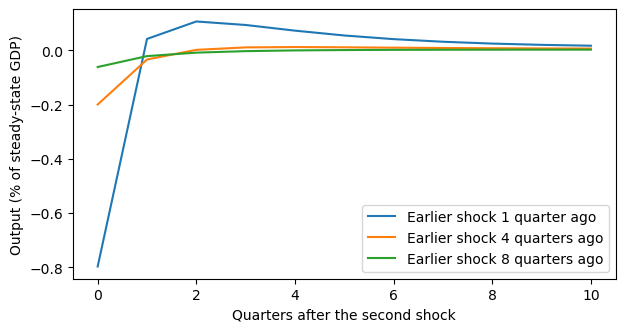

In [9]:
direct2 = np.empty((T, L))
for l in range(L):
    inherited = (single2["dF"][l], single2["d2F"][l])
    joint = second_order(backward, forward, shifted(u, l, T)+u, initial_F=inherited)
    direct2[:, l] = (joint["d2A"]-single2["d2A"][l:l+T]-single2["d2A"][:T])/2
Y2 = np.linalg.solve(J, -direct2)
print(f"Largest second-order asset-market residual: {np.max(abs(J @ Y2+direct2)):.2e}")

for l in (1, 4, 8):
    plt.plot(100*epsilon**2*Y2[:11, l], label=f"Earlier shock {l} quarter{'s' if l != 1 else ''} ago")
plt.xlabel("Quarters after the second shock"); plt.ylabel("Output (% of steady-state GDP)")
plt.legend();

The negative impact history effect becomes much smaller as the lag grows from one to four to eight quarters. The full array retains these interactions at every lag below 100 quarters, even when they are too small to distinguish in this plot.

We now have the complete second-order solution: `Y1` gives the first-order output response, `Y2` contains all second-order size and history derivatives, and `Y_risk` stores the second derivative of risky-steady-state output with respect to anticipated risk, $Y_{\sigma\sigma}$. With analytical differentiation, this complete second-order calculation takes only seconds. Notebook 3 will combine these derivatives with a realized sequence of innovations to simulate output.

## 3. Third-order terms needed for moments

We next use the solution to calculate output variance and first autocovariance. Although we have the full second-order solution, improving these moments beyond the first-order approximation also requires some third-order information: products of two quadratic responses and products of a linear and a cubic response both contribute at order $\sigma^4$.

Under the paper's Gaussian-moment assumption, **Proposition 6** shows that fifth-order-accurate covariances require only the third-order derivatives $Y_{ijj}$ and $Y_{\sigma\sigma i}$, alongside the first- and second-order solution. We can obtain these by extending the two-shock calculation above, without working through every combination of three shock dates.

### Mixed size and history effects

For shocks $x$ at date $-l$ and $y$ at date 0, we now want the mixed derivatives $Y_{xxy}$ and $Y_{xyy}$. Notebook 1 needed only their sum, but the moment calculations here require them separately. As at second order, we first work through two consecutive shocks, then repeat the calculation at other lags.

We start with the single-shock calculation. To obtain third derivatives, we now include the second-order income response `u2` as well as the first-order response `u`.

In [10]:
single3 = third_order(backward, forward, shifted(u, 0, T+L-1), shifted(u2, 0, T+L-1))

We will store the mixed output derivatives in `Y_xyy[t, l]` and `Y_xxy[t, l]`. In the paper's shock-age notation, these are $Y_{t+l,t,t}$ and $Y_{t,t+l,t+l}$, supplying both orderings of $Y_{ijj}$ needed for moments.

At lag zero, both arrays contain the cubic size effect $Y_{ttt}$. We obtain it directly from `single3` with the same GE solve used at second order.

In [11]:
Y_xyy, Y_xxy = np.empty((2, T, L))
Y_xyy[:, 0] = Y_xxy[:, 0] = np.linalg.solve(J, -single3["d3A"][:T])

Now let the earlier shock arrive one quarter before the current shock. To separate $Y_{xxy}$ and $Y_{xyy}$, we calculate the household response along both $(x,y)=(\nu,\nu)$ and $(\nu,-\nu)$.

Each `third_order` call takes the first- and second-order input responses along that path. At first order, we add or subtract the two shocks' responses. At second order, we add their size effects and then add or subtract twice the history effect already stored in `Y2[:, l]`. As before, we shift the earlier shock's responses and carry forward its distribution.

In [12]:
l = 1
old_u, old_u2 = shifted(u, l, T), shifted(u2, l, T)
u_xy = np.zeros_like(u)
u_xy[:, 1] = Y2[:, l]  # The history effect changes income, with r and Tr fixed.
inherited = tuple(single3[key][l] for key in ("dF", "d2F", "d3F"))

plus = third_order(backward, forward, old_u+u, old_u2+u2+2*u_xy, initial_F=inherited)
minus = third_order(backward, forward, old_u-u, old_u2+u2-2*u_xy, initial_F=inherited)

We can omit the third-order income corrections for each shock separately because they cancel in the subtraction below.

Let $A_+$ and $A_-$ denote the third asset derivatives returned by these calls. Subtracting the single-shock derivatives isolates the two interactions:
$$A_{xyy}=\frac{A_++A_--2A_{xxx}}{6},\qquad
A_{xxy}=\frac{A_+-A_--2A_{yyy}}{6}.$$
As at second order, we then solve with $J$ to offset these asset responses. The resulting income derivatives equal the output derivatives because debt has no higher-order terms.

In [13]:
A_xxx = single3["d3A"][l:l+T]
A_yyy = single3["d3A"][:T]
A_xyy = (plus["d3A"]+minus["d3A"]-2*A_xxx)/6
A_xxy = (plus["d3A"]-minus["d3A"]-2*A_yyy)/6
Y_xyy[:, l] = np.linalg.solve(J, -A_xyy)
Y_xxy[:, l] = np.linalg.solve(J, -A_xxy)

We now repeat this calculation for every positive lag $l<L$.

Alongside the output derivatives, we save $V_{a,xyy}$ for the time-varying precautionary effect in **Proposition 4**. This tells us how the earlier shock changes the marginal-value curvature associated with the later innovation. We obtain it with the same polarization, then add the effect of the GE income correction.

In [14]:
tvp_forcing = np.zeros((T,)+backward.shape)

for l in range(1, L):
    # Single-shock size effects are old_u2 and u2; u_xy is the history effect between shocks.
    old_u, old_u2 = shifted(u, l, T), shifted(u2, l, T)
    u_xy = np.zeros_like(u)
    u_xy[:, 1] = Y2[:, l]
    inherited = tuple(single3[key][l] for key in ("dF", "d2F", "d3F"))
    plus = third_order(backward, forward, old_u+u, old_u2+u2+2*u_xy, initial_F=inherited)
    minus = third_order(backward, forward, old_u-u, old_u2+u2-2*u_xy, initial_F=inherited)
    # Polarization isolates the mixed asset derivatives, as at second order.
    A_xxx = single3["d3A"][l:l+T]
    A_yyy = single3["d3A"][:T]
    A_xyy = (plus["d3A"]+minus["d3A"]-2*A_xxx)/6
    A_xxy = (plus["d3A"]-minus["d3A"]-2*A_yyy)/6
    Y_xyy[:, l] = np.linalg.solve(J, -A_xyy)
    Y_xxy[:, l] = np.linalg.solve(J, -A_xxy)

    # Save V_a,xyy for future risk: the same polarization plus the GE income correction.
    # The earlier shock affects marginal value through its remaining income path,
    # not through the inherited distribution.
    old = third_order(backward, forward, old_u, old_u2)
    direct_Va = (plus["d3Va0"]+minus["d3Va0"]-2*old["d3Va0"])/6
    correction = np.zeros_like(u)
    correction[:, 1] = Y_xyy[:, l]
    # Risk at date l enters the backward equation's expectations at date l-1.
    tvp_forcing[l-1] = direct_Va+first_order(backward, forward, correction)["dVa0"]

### Risk changes shock transmission

Anticipated risk changes the response to a debt shock partly because households start from a different steady state, and partly because the shock changes their exposure to future risk. We begin with the **RSS effect**, which keeps the risky steady state's expectation shift in place while introducing the debt shock, as in notebook 1. The perturbed steady state supplies both the inherited distribution and continuation marginal value, whose derivatives enter as initial and terminal conditions below.

We can calculate this with `second_order` because we differentiate once with respect to the debt innovation and once with respect to the expectation shift. The latter has size $\sigma^2/2$, so for a debt shock of size $\nu$ their interaction gives a third-order contribution proportional to $\sigma^2\nu/2$. Polarization isolates this interaction, and solving with $J$ gives the income correction that keeps assets on the given debt path.

In [15]:
risk_u = np.broadcast_to(rss_du, u.shape)
forcing = np.broadcast_to(Va00, (T,)+backward.shape)
# The steady-state marginal-value shift persists beyond the final date.
terminal_risk = (stationary["dVa"], np.zeros(backward.shape))
initial_risk = (stationary["dF"], np.zeros(backward.shape))
risk_only = second_order(backward, forward, risk_u, initial_F=initial_risk,
                         Va_forcing=forcing, Va_terminal=terminal_risk)
risk_and_shock = second_order(backward, forward, risk_u+u, initial_F=initial_risk,
                              Va_forcing=forcing, Va_terminal=terminal_risk)
rss_assets = (risk_and_shock["d2A"]-risk_only["d2A"]-single2["d2A"][:T])/2
Y_rss = np.linalg.solve(J, -rss_assets)


For the **time-varying precautionary effect (TVP)**, we now use the marginal-value derivatives saved from the two-shock calculation. Unlike in the iid partial-equilibrium example in notebook 1, the debt shock changes future equilibrium income paths and hence the marginal-value curvature associated with later innovations. The resulting change in expected marginal value affects desired saving today, so income must again adjust to keep assets on the given debt path.

For a shock today, `tvp_forcing[l-1]` contains the marginal-value derivative associated with risk at date `l`: the backward equation at date `l-1` takes expectations about date `l`. We now use this forcing to solve for the income adjustment with no additional debt innovation. Adding this to the RSS effect gives the total risk contribution $\sigma^2\nu(Y_{\mathrm{rss}}+Y_{\mathrm{tvp}})/2$ to the response to a debt shock of size $\nu$.

The plot uses a debt shock of size $\epsilon=0.10$ and anticipated risk $\sigma=0.05$, as in the second-order decomposition. The RSS and TVP contributions add up to the total risk effect, with all three measured as percentages of steady-state GDP.

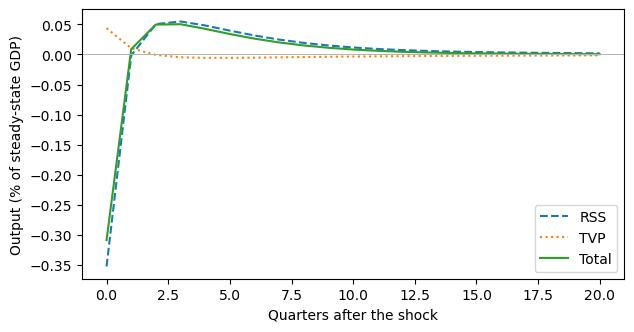

In [16]:
tvp = first_order(backward, forward, np.zeros_like(u), Va_forcing=tvp_forcing)
Y_tvp = np.linalg.solve(J, -tvp["dA"])
Y_risk_transmission = Y_rss+Y_tvp

epsilon, sigma = 0.10, 0.05
for response, label, style in [(Y_rss, "RSS", "--"), (Y_tvp, "TVP", ":"),
                               (Y_risk_transmission, "Total", "-")]:
    plt.plot(np.arange(21), 100*sigma**2*epsilon*response[:21]/2, style, label=label)
plt.axhline(0., color="0.7", linewidth=0.7)
plt.xlabel("Quarters after the shock"); plt.ylabel("Output (% of steady-state GDP)")
plt.legend();

The RSS effect reduces impact spending and raises it in later quarters, while TVP partly offsets this pattern. For the shock and risk levels plotted here, their impact contributions are about $-0.35\%$ and $0.04\%$ of steady-state GDP. The net reduction of $0.31\%$ of GDP is about 12% of the first-order impact response of $2.51\%$ of GDP. Most of the change in transmission therefore comes from the RSS effect.

The precautionary mechanism is similar to the one we saw in PE: households are less likely to be at the borrowing constraint and spend less of an additional dollar of income on impact. Here, however, aggregate assets are fixed by government debt, and income falls to clear the asset market. Precautionary behavior still changes the distribution, leaving fewer households at the constraint even though average assets are unchanged.

## 4. Output variance and first autocovariance

We can now calculate output variance and first autocovariance directly from the derivatives already obtained. Writing the lag as $h$, we obtain variance at $h=0$ and the first autocovariance at $h=1$. For innovations with Gaussian moments, **Proposition 6** gives
$$\operatorname{Cov}(Y_t,Y_{t-h})=\sigma^2\Sigma_{h,2}+\sigma^4\Sigma_{h,4}+O(\sigma^6),$$
with
$$\Sigma_{h,2}=\sum_i Y_{h+i}Y_i,$$
$$\begin{aligned}
\Sigma_{h,4}={}&\frac12\sum_{i,j}Y_{h+i,h+j}Y_{ij}\\
&+\frac12\sum_i\left(Y_{h+i}Y_{\sigma\sigma i}+Y_{\sigma\sigma,h+i}Y_i\right)\\
&+\frac12\sum_{i,j}\left(Y_{h+i}Y_{ijj}+Y_{h+i,jj}Y_i\right).
\end{aligned}$$
The three contributions to $\Sigma_{h,4}$ come from quadratic size and history effects, risk transmission, and cubic size and history effects, respectively. A second-order solution supplies only the first of these contributions.

For the cubic contribution, we can first sum over the repeated shock index:
$$S_i=\sum_j Y_{ijj},\qquad
\Sigma_{h,4}^{\mathrm{cubic}}=\frac12\sum_i\left(Y_{h+i}S_i+Y_iS_{h+i}\right).$$
The two sums in $\Sigma_{h,4}^{\mathrm{cubic}}$ are dot products between the first-order response and $S$, with one or the other shifted by $h$.

We store $S_i$ in `Y3_sum[i]`. `Y_xxy[t, l]` contributes at age $i=t$, while `Y_xyy[t, l]` contributes at age $i=t+l$. Lag zero is included just once. The array extends through age $T+L-2$ because the earlier shock can already be $L-1$ quarters old when the $T$-period response begins.

In [17]:
Y3_sum = np.zeros(T+L-1)
Y3_sum[:T] = Y_xyy[:, 0]
for l in range(1, L):
    Y3_sum[:T] += Y_xxy[:, l]
    Y3_sum[l:l+T] += Y_xyy[:, l]

We now evaluate the covariance formula. In the quadratic term, shifting both shock ages by $h$ shifts the response date by $h$ and leaves the lag unchanged. Positive lags appear twice in the symmetric sum, canceling the factor of one-half; lag zero retains that factor.

In [18]:
def covariance_coefficients(h):
    n = T-h
    second = Y1[h:] @ Y1[:n]
    quadratic = np.sum(Y2[h:, 0]*Y2[:n, 0])/2
    quadratic += np.sum(Y2[h:, 1:]*Y2[:n, 1:])
    risk = (Y1[h:] @ Y_risk_transmission[:n]+Y_risk_transmission[h:] @ Y1[:n])/2
    # The second product retains cubic shock ages beyond T-1 that overlap the lagged linear response.
    cubic = (Y1[h:] @ Y3_sum[:n]+Y3_sum[h:h+T] @ Y1)/2
    return second, quadratic, risk, cubic

Below we plot the variance ($h=0$) and first autocovariance ($h=1$), divided by shock variance $\sigma^2$. The **Third-order accurate** curve uses the first-order solution and is constant after this normalization. The **Fifth-order accurate** curve adds the full $\sigma^4\Sigma_{h,4}$ correction. The pruned second-order curve retains only the quadratic size and history contribution to $\Sigma_{h,4}$. These panels correspond to paper **Figure B.7(a,b)**.

Lag 0, sigma=0.05: third-order accurate 0.0002263, fifth-order accurate 0.0002285
Lag 1, sigma=0.05: third-order accurate 0.0001232, fifth-order accurate 0.0001250


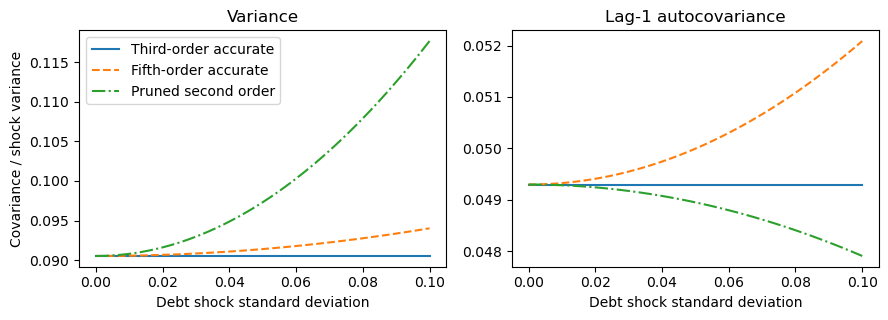

In [19]:
# Paper Figure B.7(a,b).
sigmas = np.linspace(0., 0.10, 51)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for h, ax in enumerate(axes):
    second, quadratic, risk, cubic = covariance_coefficients(h)
    ax.plot(sigmas, np.full_like(sigmas, second), "C0-", label="Third-order accurate")
    ax.plot(sigmas, second+sigmas**2*(quadratic+risk+cubic), "C1--", label="Fifth-order accurate")
    ax.plot(sigmas, second+sigmas**2*quadratic, "C2-.", label="Pruned second order")
    ax.set(xlabel="Debt shock standard deviation", title=("Variance", "Lag-1 autocovariance")[h])
    print(f"Lag {h}, sigma={sigma:.2f}: third-order accurate {sigma**2*second:.7f}, "
          f"fifth-order accurate {sigma**2*second+sigma**4*(quadratic+risk+cubic):.7f}")
axes[0].set_ylabel("Covariance / shock variance")
axes[0].legend()
fig.tight_layout();

The quadratic terms alone, in "pruned second order", substantially overstate the correction to variance. Their contribution is largely offset by the interaction of the first-order response with cubic size and history effects and risk transmission. For the first autocovariance, the quadratic correction is negative, but the full correction is positive. Simply calculating moments of the second-order solution would therefore miss even the direction of this change.

At $\sigma=0.05$, the full corrections raise variance by about 1% and the first autocovariance by about 1.4% relative to the first-order solution. We have obtained these moments from the analytical derivatives without calculating interactions among three distinct shock dates. Notebook 3 uses `sequence_space/solution.py` to automate the constructions and adds those interactions when simulating the full cubic solution.